# CW3: PORTFOLIO FACTOR MODELS AND STYLE ANALYSIS 

Welcome to your last coursework for Portfolio Management. In this coursework you will explore Factor Models and their use to analyse returns and investment styles. 

Factor analysis stands as a pivotal tool in modern portfolio theory, offering a systematic approach to decompose a portfolio's observed returns into distinct explanatory variables or factors, helping to understand the underlying factors that drive asset returns. This analytical framework not only enhances our comprehension of asset performance but also aids in constructing more robust investment strategies.

This courseworks builds on top of previous courseworks and course lectures. Here, you will start by analyzing the returns of an individual company, namely Berkshire Hathaway. By applying factor analysis to this renowned conglomerate's performance data, we aim to unravel the latent factors influencing its returns, thereby gaining deeper insights into its investment strategies and market positioning. Then you will learn about how to perform a Sharpe Style Analysis and apply it to broader industries. Finally, you will extend the exploration beyond to encompass broader investment players and industries to systematically uncover the dominant factors driving returns and investment styles over time. 

You will be guided with main new conceptual elements, and your task is to complete, extend and explain the processes to produce the requested analysis. 
You must: 
- Complete the code and the requested analysis.
- Explain main concepts and interpret the results.
- Create a report that naturally constructs the analysis of Berkshire Hathaway, additional industries, and the selected additional companies.
- Upload your code and report as pdf files, with a maximum of 3,500 words for the report.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm 
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import yfinance as yf

## Factor Analysis 

Factor analysis is a statistical method used to identify underlying relationships between observed variables by grouping them into factors or dimensions. The main goal of factor analysis is to uncover the latent structure behind observed data, which can be useful for understanding the data better, identifying patterns, or creating predictive models.

In portfolio analysis, factor analysis is used to identify the common drivers (e.g., market risk, industry-specific factors, or macroeconomic influences), also called explanatory variables, that affect the returns of assets in a portfolio. It helps in understanding how different factors contribute to the overall performance of a portfolio, allowing for better risk management and asset allocation.

Therefore, to perform a Factor Analysis we need to take a set of observed returns and decompose it into a set of explanatory variables/returns. We will start by trying to explain the returns of a famous company: Berkshire Hathaway.

In [2]:
brka_d = pd.read_csv("../data/brka_d_ret.csv", parse_dates=True, index_col=0) 
brka_d.head() 

,BRKA
DATE,
1990-01-02,-0.005764
1990-01-03,0.000000
1990-01-04,0.005797
1990-01-05,-0.005764
1990-01-08,0.000000


As you can see, these are daily returns, and we need to convert them to monthly returns. Obtain the monthly returns.

Hint: A way to do this is to apply a compound function from previous courseworks y using the .resample method, which allows you to run an aggregation function on each group of returns in a time series, passing as groupping rule 'M' which means monthly (consult the pandas documentation for reference).

In [3]:
def compound(r): 
   """ 
   returns the result of compounding the set of returns in r 
   """ 
   return (1 + r).prod() - 1

In [4]:
brka_m = brka_d.resample('ME').apply(compound).to_period('M')
brka_m.head()

#1990-01	-0.140634
#1990-02	-0.030852

,BRKA
DATE,
1990-01,-0.140634
1990-02,-0.030852
1990-03,-0.069204
1990-04,-0.003717
1990-05,0.067164


We already have our monthly returns, this is our target variable to decompose/explain. Next, we need to load the explanatory variables, and for this coursework we will be using the Fama-French factors monthly returns. 

In [5]:
fff = pd.read_csv("../data/F-F_Research_Data_Factors_m.csv", header=0, index_col=0, na_values=-99.99)/100 
fff.index = pd.to_datetime(fff.index, format="%Y%m").to_period('M')    
fff.head() 

,Mkt-RF,SMB,HML,RF
1926-07,0.0296,-0.0230,-0.0287,0.0022
1926-08,0.0264,-0.0140,0.0419,0.0025
1926-09,0.0036,-0.0132,0.0001,0.0023
1926-10,-0.0324,0.0004,0.0051,0.0032
1926-11,0.0253,-0.0020,-0.0035,0.0031


What does each of these columns represent?

Estas columnas representan los rendimientos mensuales de los factores de Fama-French, que son comúnmente utilizados en modelos de valoración de activos para explicar los rendimientos de las acciones.

1. Mkt-RF (Mercado menos tasa libre de riesgo)
Representa el rendimiento excedente del mercado sobre la tasa libre de riesgo.
Es decir, cuánto más rindió el mercado en comparación con una inversión sin riesgo.
Este factor captura la sensibilidad del activo frente a los movimientos generales del mercado.

2. SMB (Small Minus Big)
Representa la prima por tamaño.
Es la diferencia de rendimiento entre portafolios de acciones de empresas pequeñas (small caps) y grandes (big caps).
Si un activo tiene una beta positiva frente a este factor, significa que su comportamiento es más similar al de las empresas pequeñas.

3. HML (High Minus Low)
Representa la prima por estilo de inversión (valor vs. crecimiento).
Es la diferencia de rendimiento entre acciones de valor (alto valor libro/mercado) y acciones de crecimiento (bajo valor libro/mercado).
Una carga positiva indica mayor exposición a acciones de valor.

4. RF (Risk-Free Rate / Tasa libre de riesgo)
Es la tasa mensual libre de riesgo, normalmente basada en bonos del Tesoro a corto plazo (como de 1 mes).
Se usa para calcular los rendimientos en exceso (como Mkt-RF) y para evaluar el desempeño ajustado por riesgo.

Estos factores conforman el modelo de tres factores de Fama-French, una extensión del CAPM que añade los efectos de tamaño y valor para explicar mejor los rendimientos de los activos.

### CAPM

We will start by decomposing the observed BRKA returns from 1990 to May 2012 into the portion that's due to the market and the rest that is not due to the market. This, as you may remember, implies using the CAPM as the explanatory model:

$$R_{brka,t}-R_{f,t}=\alpha + \beta(R_{mkt,t}-R_{f,t})+\epsilon_t $$

CAPM is basically a Linear regression, and as such, we can fit a linear regression using the stats models api we have previously load.

Notice CAPM makes use of excess of return and not just returns. Our FF dataset already contains the excess of return of the market in Mkt-RF column and the RF rate for the periods of interes, but we have not computed the excess of return of BRKA yet. Additionaly, as we are fitting a line, we need to set a constant for the explanatory variables, which is basically setting a 1 as an additional variable which multiplied for estimated coefficient, just returns the coefficiet, it is:

$$R_{brka,t}-R_{f,t}=\alpha*(1) + \beta(R_{mkt,t}-R_{f,t})+\epsilon_t $$

This works for setting all explanatory variables in a matrix (X) and coefficients as a vector, which is used by many libraries for improved computation.

Obtain the excess of return of the Market and BRKA over the Risk-Free rate for the period from 1990 to 2012-05. 

In [6]:
data = pd.concat([brka_m, fff], axis=1).dropna()
data = data.loc["1990-01":"2012-05"]

brka_excess = data.iloc[:, 0] - data["RF"]
mkt_excess = data["Mkt-RF"]
exp_var = mkt_excess.to_frame()
exp_var["Constant"] = 1 #set the constant explanatory variable as 1

In [7]:
exp_var.head()

,Mkt-RF,Constant
1990-01,-0.0785,1
1990-02,0.0111,1
1990-03,0.0183,1
1990-04,-0.0336,1
1990-05,0.0842,1


El DataFrame contiene lo siguiente:

- **Mkt-RF**: Exceso de rendimiento del mercado sobre la tasa libre de riesgo. Esta es la variable principal en el modelo CAPM.
- **Constant**: Una columna con valores iguales a 1. Se utiliza para estimar el intercepto (**α**) en la regresión lineal.

Esto indica que, por ejemplo, en enero de 1990 el mercado tuvo un rendimiento **7.85% por debajo** de la tasa libre de riesgo, y la constante permite al modelo estimar un intercepto  (**α**).

Now, use statsmodels to fit a linear regression that uses our explanatory variables to predict the excess of returns of BRKA:

In [8]:
lm = sm.OLS(brka_excess, exp_var).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     48.45
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.62e-11
Time:                        15:54:07   Log-Likelihood:                 388.47
No. Observations:                 269   AIC:                            -772.9
Df Residuals:                     267   BIC:                            -765.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         0.5402      0.078      6.961      0.000       0.387       0.693
Constant       0.0061      0.004      1.744      0.082      -0.001       0.013
==============================================================================
Omnibus:                       45.698   Durbin-Watson:                   2.079
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              102.573
Skew:                           0.825   Prob(JB):                     5.33e-23
Kurtosis:                       5.535   Cond. No.                         22.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

This is a full statistical report of the model, which you will learn to analyze further during courses in next semesters. At this moment, we are interested in the values of the coefficients for our explanatory variables. Do you remmeber what these values mean? If so, explain.

One way to interpret the coefficients would be to say that the CAPM benchmark consists of 54 cents in the market and 46 cents in T-Bills, i.e. each dollar in the Berkshire Hathaway portfolio is equivalent to 46 cents in T-Bills and 54 cents in the market. Relative to this, Berkshire Hathaway is adding 0.61% (per month) although the degree of statistical significance is not very high.

### Interpretación de los coeficientes:

El modelo CAPM estima que los rendimientos en exceso de Berkshire Hathaway pueden explicarse parcialmente por el exceso de rendimiento del mercado, con una beta de 0.54. Esto implica que Berkshire tiene una exposición moderada al riesgo de mercado, similar a una cartera que invierte 54% en el mercado y 46% en activos libres de riesgo (T-Bills).

Adicionalmente, el modelo estima un alpha de 0.61% mensual, lo cual sugiere que Berkshire Hathaway podría estar generando un rendimiento adicional no explicado por el mercado. Sin embargo, este valor no es estadísticamente significativo al nivel del 5%, aunque lo es al 10%, por lo que debe interpretarse con cautela.

### Interpretación económica del CAPM

Una forma útil de interpretar los coeficientes del modelo CAPM es mediante una analogía con asignación de activos:

- El coeficiente **β = 0.54** puede interpretarse como que **cada dólar invertido en Berkshire Hathaway se comporta como 54 centavos invertidos en el mercado**, y el resto (46 centavos) como si estuviera en bonos del gobierno (T-Bills), los cuales tienen bajo riesgo.
- Este tipo de comportamiento es típico de una empresa o fondo **con exposición parcial al riesgo del mercado**, es decir, **menos volátil que el mercado en general**.

Además, el modelo estima un **α (alpha) de 0.61% mensual**, lo cual sugiere que BRKA generó, en promedio, un rendimiento mensual adicional por encima de lo que predice el modelo CAPM. Sin embargo, este valor **no es estadísticamente significativo al nivel del 5%**, por lo que debe tomarse con cautela.

Esto apoya la idea de que BRKA **no se comporta exactamente como el mercado** y podría estar aprovechando otras fuentes de rendimiento no explicadas por el CAPM, como factores de valor o tamaño, lo cual será explorado con el modelo de Fama-French.


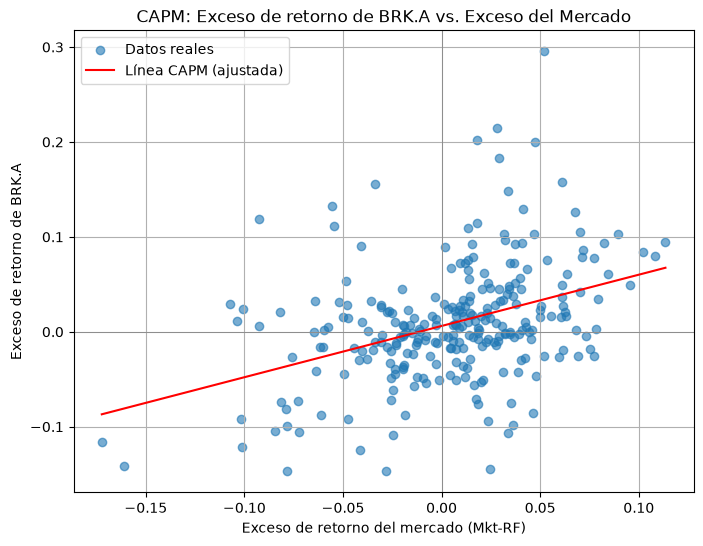

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(exp_var["Mkt-RF"], brka_excess, alpha=0.6, label="Datos reales")

x_vals = np.linspace(exp_var["Mkt-RF"].min(), exp_var["Mkt-RF"].max(), 100)
y_vals = lm.params["Constant"] + lm.params["Mkt-RF"] * x_vals
plt.plot(x_vals, y_vals, color="red", label="Línea CAPM (ajustada)")

plt.title("CAPM: Exceso de retorno de BRK.A vs. Exceso del Mercado")
plt.xlabel("Exceso de retorno del mercado (Mkt-RF)")
plt.ylabel("Exceso de retorno de BRK.A")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.legend()
plt.grid(True)
plt.show()

### Fama and French Three-Factor Model

Now, let's extend CAPM to an FF-Model by adding in some additional explanatory variables, namely Value and Size.

Take the HML and SMB variables from the fff dataset accordingly to use them to fit a new model to explain brka_excess.

In [10]:
exp_var["Value"] = data["HML"]
exp_var["Size"] = data["SMB"]
exp_var.head()

,Mkt-RF,Constant,Value,Size
1990-01,-0.0785,1,0.0087,-0.0129
1990-02,0.0111,1,0.0061,0.0103
1990-03,0.0183,1,-0.0290,0.0152
1990-04,-0.0336,1,-0.0255,-0.0050
1990-05,0.0842,1,-0.0374,-0.0257


Este nuevo DataFrame `exp_var` contiene ahora:

- **Mkt-RF**: Exceso de rendimiento del mercado sobre la tasa libre de riesgo.
- **Constant**: Columna de unos que permite estimar el intercepto (α) del modelo.
- **Value**: Factor HML (High Minus Low), que representa la diferencia de rendimiento entre acciones de valor y de crecimiento.
- **Size**: Factor SMB (Small Minus Big), que representa la diferencia entre acciones pequeñas y grandes.

#### Interpretación con los datos de enero de 1990:

Mkt-RF. El mercado tuvo un rendimiento 7.85% por debajo del libre de riesgo.

Value. Las acciones de valor superaron a las de crecimiento en 0.87%. 

Size. Las acciones grandes superaron a las pequeñas en 1.29%. 

In [11]:
lm = sm.OLS(brka_excess, exp_var).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.290
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     36.06
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           1.41e-19
Time:                        15:54:08   Log-Likelihood:                 412.09
No. Observations:                 269   AIC:                            -816.2
Df Residuals:                     265   BIC:                            -801.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         0.6761      0.074      9.155      0.000       0.531       0.821
Constant       0.0055      0.003      1.679      0.094      -0.001       0.012
Value          0.3814      0.109      3.508      0.001       0.167       0.595
Size          -0.5023      0.101     -4.962      0.000      -0.702      -0.303
==============================================================================
Omnibus:                       42.261   Durbin-Watson:                   2.146
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               67.954
Skew:                           0.904   Prob(JB):                     1.75e-15
Kurtosis:                       4.671   Cond. No.                         37.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Notice that the alpha has fallen from .61% to about 0.55% per month, and the market has moved up from 0.54 to 0.67, Why? Explain. How do you interpret the loadings on Value being positive? How do you interpret the loadings on Value being positive? Based on the results of the coefficients and your previous explanation, what can we say about the investing style of BRKA? Explain the coefficient results in money (dollar invested) terms? If we use this model to explain BRKA returns, what would be our error in money terms per month?

### Análisis del modelo Fama-French aplicado a Berkshire Hathaway

Al extender el modelo CAPM hacia el modelo de tres factores de Fama y French, observamos una mejora sustancial en la capacidad explicativa del modelo. El coeficiente de determinación $R^2$ aumentó de 15.4% a 29%, lo que indica que los factores adicionales de **valor (HML)** y **tamaño (SMB)** ayudan significativamente a entender los rendimientos de Berkshire Hathaway. Esta mejora sugiere que parte del rendimiento que en el CAPM era atribuido al *alpha* (rendimiento no explicado), ahora es absorbido por las nuevas variables explicativas.

El *alpha* estimado cae de **0.61%** a **0.55% mensual**, lo que refleja que una porción del “exceso de rendimiento” anteriormente atribuido a la habilidad del gestor (o rendimientos anómalos) ahora puede ser explicado por la exposición a factores sistemáticos como valor y tamaño. No obstante, este *alpha* sigue sin ser estadísticamente significativo al nivel del 5%, aunque se acerca al nivel del 10%, por lo que debe interpretarse con precaución.

El coeficiente de **Mkt-RF** también aumenta de 0.54 a **0.676**, lo que indica que al controlar por los otros factores, se obtiene una estimación más precisa de la sensibilidad de BRKA al mercado. Esto refleja una **exposición moderada al riesgo sistemático del mercado**, menor a la de un portafolio completamente expuesto.

En cuanto a los factores adicionales, el coeficiente de **Value (HML)** es **positivo y significativo**, lo cual es coherente con el enfoque de inversión de Berkshire Hathaway. La empresa se comporta como un portafolio con inclinación hacia **acciones de valor**, es decir, aquellas que están subvaloradas en términos contables respecto a su precio de mercado. Por otro lado, el coeficiente de **Size (SMB)** es **negativo y significativo**, lo que indica una exposición contraria al factor tamaño: BRKA **actúa como una gran empresa**, evitando el comportamiento típico de acciones de empresas pequeñas.

Interpretando los coeficientes en términos monetarios, podríamos decir que por cada dólar invertido, el comportamiento de BRKA equivale a tener aproximadamente **68 centavos expuestos al mercado**, **38 centavos en acciones de valor**, y una **posición corta de 50 centavos en empresas pequeñas**. Cabe aclarar que estos coeficientes no representan pesos de portafolio reales, sino **cargas relativas a factores** que explican el comportamiento del activo.

Finalmente, al calcular la desviación estándar de los residuos del modelo, podemos estimar el **error de predicción promedio mensual** del modelo. Este error representa la porción del rendimiento que el modelo no logra explicar. Si se desea expresarlo en términos monetarios, puede multiplicarse por un monto invertido (por ejemplo, $1,000) para tener una idea de la variabilidad mensual no explicada por los factores.


### Comparación entre CAPM y Fama-French.

Al comparar los resultados del modelo CAPM y del modelo Fama-French de tres factores aplicado a Berkshire Hathaway (BRKA), observamos los siguientes cambios importantes:

#### Disminución del Alpha: de 0.61% a 0.55% mensual

- En el modelo CAPM, el alpha era de **0.0061** (0.61%), mientras que en el modelo Fama-French bajó a **0.0055** (0.55%).
- Esta caída indica que parte del rendimiento adicional que parecía "extra" bajo CAPM, **en realidad es explicado por los factores Value y Size**.
- Además, el alpha en Fama-French **pierde significancia estadística** (p ≈ 0.094), lo que sugiere que no hay evidencia sólida de un rendimiento anormal constante.

#### Aumento del Beta de mercado: de 0.54 a 0.67

- La beta del mercado subió de 0.5402 (CAPM) a 0.6761 (FF).
- Esto se debe a que, al incluir más variables explicativas (Value y Size), el modelo puede **aislar mejor el efecto puro del mercado**, lo que permite estimar un beta más "limpio" y representativo.

#### Interpretación del loading positivo en Value (HML)

- El coeficiente del factor **Value (HML)** es positivo y significativo: **0.3814**.
- Esto indica que BRKA tiene **preferencia por acciones de valor**, es decir, acciones de empresas con alta relación entre valor contable y valor de mercado.
- Este resultado es consistente con el enfoque de inversión de Warren Buffett, quien se enfoca en empresas sólidas, subvaloradas y con fundamentos fuertes.

#### Interpretación del loading negativo en Size (SMB)

- El coeficiente de **Size (SMB)** es **-0.5023**, lo que implica que BRKA **evita acciones de empresas pequeñas** y prefiere empresas grandes (big-cap).
- Esto también concuerda con su estrategia, ya que BRKA invierte en compañías grandes, estables y con historial comprobado.


### Interpretación en términos de dinero invertido

Podemos interpretar los coeficientes como si BRKA fuera una mezcla de portafolios:

- **67 centavos por dólar están expuestos al mercado**
- **38 centavos están en acciones de valor**
- **-50 centavos** implican una posición **negativa en acciones pequeñas**, es decir, **BRKA se comporta como si apostara en contra del segmento small-cap**
- El alpha de **0.55%** mensual representa el retorno adicional que el modelo no logra explicar

You can also extract information from the returned lm object by using lm.params and other methods.

Now, write a function to automatically fit a linear regression.

In [12]:
import statsmodels.api as sm 
def regress(dep_var, exp_vars, alpha=True):
    exp_vars = exp_vars.copy()
    if alpha:
        exp_vars = sm.add_constant(exp_vars, has_constant='add')
    common_idx = dep_var.index.intersection(exp_vars.index)
    return sm.OLS(dep_var.loc[common_idx], exp_vars.loc[common_idx]).fit()

Now, we have just analyzed a selected time frame from the original dataframe, where we have more information from 2012 on. Have the results hold? Perform the CAPM and FF analysis for dates after May 2012, and then for the whole data and compare the results in these different time frames.


In [13]:
#Datos post-2012
data_post = pd.concat([brka_m, fff], axis=1).dropna()
data_post = data_post.loc["2012-06":]

#Calcular exceso de retorno de BRKA
brka_excess_post = data_post["BRKA"] - data_post["RF"]

#Calcular exceso de retorno del mercado
mkt_excess_post = data_post[["Mkt-RF"]] 

#Ajustar modelo CAPM usando regress()
lm_post = regress(brka_excess_post, mkt_excess_post)
lm_post.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.494
Model:                            OLS   Adj. R-squared:                  0.487
Method:                 Least Squares   F-statistic:                     75.12
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           5.26e-13
Time:                        15:54:08   Log-Likelihood:                 174.42
No. Observations:                  79   AIC:                            -344.8
Df Residuals:                      77   BIC:                            -340.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0038      0.003      1.184      0.240      -0.003       0.010
Mkt-RF         0.8460      0.098      8.667      0.000       0.652       1.040
==============================================================================
Omnibus:                        2.502   Durbin-Watson:                   1.821
Prob(Omnibus):                  0.286   Jarque-Bera (JB):                2.332
Skew:                           0.338   Prob(JB):                        0.312
Kurtosis:                       2.498   Cond. No.                         32.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
# Seleccionar las variables explicativas del modelo FF
ff_explanatory_post = data_post[["Mkt-RF", "HML", "SMB"]]

# Ajustar modelo Fama-French usando regress()
lm_ff_post = regress(brka_excess_post, ff_explanatory_post)
lm_ff_post.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.620
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     40.80
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           9.61e-16
Time:                        15:54:08   Log-Likelihood:                 185.76
No. Observations:                  79   AIC:                            -363.5
Df Residuals:                      75   BIC:                            -354.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0028      0.003      0.999      0.321      -0.003       0.008
Mkt-RF         0.9359      0.089     10.501      0.000       0.758       1.113
HML            0.4587      0.119      3.851      0.000       0.221       0.696
SMB           -0.4082      0.119     -3.444      0.001      -0.644      -0.172
==============================================================================
Omnibus:                        1.302   Durbin-Watson:                   2.102
Prob(Omnibus):                  0.522   Jarque-Bera (JB):                1.292
Skew:                           0.207   Prob(JB):                        0.524
Kurtosis:                       2.529   Cond. No.                         47.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [15]:
# Datos de todo el periodo
data_full = pd.concat([brka_m, fff], axis=1).dropna()

# Calcular exceso de retorno de BRKA
brka_excess_full = data_full["BRKA"] - data_full["RF"]

# Calcular exceso de retorno del mercado
mkt_excess_full = data_full[["Mkt-RF"]]  

# Ajustar modelo CAPM usando regress()
lm_capm_full = regress(brka_excess_full, mkt_excess_full)
lm_capm_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.179
Method:                 Least Squares   F-statistic:                     76.69
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           9.03e-17
Time:                        15:54:08   Log-Likelihood:                 535.44
No. Observations:                 348   AIC:                            -1067.
Df Residuals:                     346   BIC:                            -1059.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0061      0.003      2.150      0.032       0.001       0.012
Mkt-RF         0.5779      0.066      8.757      0.000       0.448       0.708
==============================================================================
Omnibus:                       66.402   Durbin-Watson:                   2.074
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              197.134
Skew:                           0.858   Prob(JB):                     1.56e-43
Kurtosis:                       6.263   Cond. No.                         23.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [16]:
# Seleccionar las variables explicativas del modelo Fama-French
ff_explanatory_full = data_full[["Mkt-RF", "HML", "SMB"]]

# Ajustar modelo Fama-French usando regress()
lm_ff_full = regress(brka_excess_full, ff_explanatory_full)
lm_ff_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     53.29
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.59e-28
Time:                        15:54:08   Log-Likelihood:                 567.01
No. Observations:                 348   AIC:                            -1126.
Df Residuals:                     344   BIC:                            -1111.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0052      0.003      1.991      0.047    6.18e-05       0.010
Mkt-RF         0.7096      0.063     11.350      0.000       0.587       0.833
HML            0.4053      0.090      4.494      0.000       0.228       0.583
SMB           -0.4829      0.085     -5.696      0.000      -0.650      -0.316
==============================================================================
Omnibus:                       64.922   Durbin-Watson:                   2.162
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              138.061
Skew:                           0.962   Prob(JB):                     1.05e-30
Kurtosis:                       5.413   Cond. No.                         38.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Next, download returns from Yahoo Finance for one ticker of your choice (e.g. TSLA, MSFT, AAPL, etc.). Perform an analysis of the data and behavior of the returns. Run forecasting regressions using the given FF dataset variables, first try to explain the excess return with the CAMP and then use a FF model.

In [17]:
Msft_d = yf.download("MSFT", start="1987-01-01", end="2025-04-02", interval="1mo", auto_adjust=True)["Close"]
Msft_d.index = Msft_d.index.to_period("M")
Msft_d = pd.DataFrame(Msft_d)
Msft_d.columns = ["MSFT"]
Msft_d.head()

[*********************100%***********************]  1 of 1 completed


,MSFT
Date,
1987-01,0.154122
1987-02,0.161763
1987-03,0.203916
1987-04,0.219196
1987-05,0.242908


In [18]:
Msft_returns = pd.DataFrame({"Microsoft": Msft_d["MSFT"].pct_change()})
Msft_returns = Msft_returns.dropna()
Msft_returns.head()

,Microsoft
Date,
1987-02,0.049574
1987-03,0.260588
1987-04,0.074934
1987-05,0.108174
1987-06,-0.114967


In [19]:
#1990 a 2012 CAPM
msft_excess = pd.DataFrame(Msft_returns["Microsoft"] - fff["RF"], columns=["MSFT"])
msft_excess = msft_excess.loc["1990":"2012-05"].copy()
mkt_excess_msft = fff.loc["1990":"2012-05", ["Mkt-RF"]].copy()

capm_msft = regress(msft_excess, mkt_excess_msft)
capm_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.334
Model:                            OLS   Adj. R-squared:                  0.331
Method:                 Least Squares   F-statistic:                     133.7
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.45e-25
Time:                        15:54:08   Log-Likelihood:                 300.44
No. Observations:                 269   AIC:                            -596.9
Df Residuals:                     267   BIC:                            -589.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0110      0.005      2.265      0.024       0.001       0.021
Mkt-RF         1.2446      0.108     11.562      0.000       1.033       1.457
==============================================================================
Omnibus:                       28.659   Durbin-Watson:                   2.263
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               74.071
Skew:                           0.466   Prob(JB):                     8.24e-17
Kurtosis:                       5.396   Cond. No.                         22.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
#1990 a 2012 FF
mkt_excess_msft["Value"] = fff.loc["1990":"2012-05", "HML"]
mkt_excess_msft["Size"] = fff.loc["1990":"2012-05", "SMB"]

resumen_msft = regress(msft_excess, mkt_excess_msft)
resumen_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.408
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     60.80
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           6.11e-30
Time:                        15:54:08   Log-Likelihood:                 316.28
No. Observations:                 269   AIC:                            -624.6
Df Residuals:                     265   BIC:                            -610.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0140      0.005      3.012      0.003       0.005       0.023
Mkt-RF         1.1691      0.105     11.087      0.000       0.962       1.377
Value         -0.8927      0.155     -5.751      0.000      -1.198      -0.587
Size          -0.2668      0.145     -1.845      0.066      -0.551       0.018
==============================================================================
Omnibus:                       24.180   Durbin-Watson:                   2.189
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               47.752
Skew:                           0.476   Prob(JB):                     4.27e-11
Kurtosis:                       4.831   Cond. No.                         37.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [21]:
#2012 a 2018 CAPM
msft_excess = pd.DataFrame(Msft_returns["Microsoft"] - fff["RF"], columns=["MSFT"])
msft_excess = msft_excess.loc["2012-06":].copy()
mkt_excess_msft = fff.loc["2012-06":, ["Mkt-RF"]].copy()

capm_msft = regress(msft_excess, mkt_excess_msft)
capm_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.249
Model:                            OLS   Adj. R-squared:                  0.240
Method:                 Least Squares   F-statistic:                     25.57
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.82e-06
Time:                        15:54:08   Log-Likelihood:                 123.18
No. Observations:                  79   AIC:                            -242.4
Df Residuals:                      77   BIC:                            -237.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0098      0.006      1.599      0.114      -0.002       0.022
Mkt-RF         0.9441      0.187      5.056      0.000       0.572       1.316
==============================================================================
Omnibus:                        7.707   Durbin-Watson:                   2.534
Prob(Omnibus):                  0.021   Jarque-Bera (JB):               12.152
Skew:                           0.290   Prob(JB):                      0.00230
Kurtosis:                       4.832   Cond. No.                         32.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [22]:
#2012 a 2018 FF
mkt_excess_msft["Value"] = fff.loc["2012-06":, "HML"]
mkt_excess_msft["Size"] = fff.loc["2012-06":, "SMB"]

resumen_msft = regress(msft_excess, mkt_excess_msft)
resumen_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.358
Model:                            OLS   Adj. R-squared:                  0.333
Method:                 Least Squares   F-statistic:                     13.96
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.54e-07
Time:                        15:54:08   Log-Likelihood:                 129.38
No. Observations:                  79   AIC:                            -250.8
Df Residuals:                      75   BIC:                            -241.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0074      0.006      1.285      0.203      -0.004       0.019
Mkt-RF         1.1198      0.182      6.155      0.000       0.757       1.482
Value         -0.0445      0.243     -0.183      0.855      -0.529       0.440
Size          -0.8575      0.242     -3.543      0.001      -1.340      -0.375
==============================================================================
Omnibus:                        5.059   Durbin-Watson:                   2.427
Prob(Omnibus):                  0.080   Jarque-Bera (JB):                6.961
Skew:                           0.071   Prob(JB):                       0.0308
Kurtosis:                       4.447   Cond. No.                         47.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [23]:
#Todos los tiempos CAPM
msft_excess = pd.DataFrame(Msft_returns["Microsoft"] - fff["RF"], columns=["MSFT"])
msft_excess = msft_excess.loc["1990":].copy()
mkt_excess_msft = fff.loc["1990":, ["Mkt-RF"]].copy()

capm_msft = regress(msft_excess, mkt_excess_msft)
capm_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.323
Model:                            OLS   Adj. R-squared:                  0.321
Method:                 Least Squares   F-statistic:                     165.1
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           3.71e-31
Time:                        15:54:08   Log-Likelihood:                 412.91
No. Observations:                 348   AIC:                            -821.8
Df Residuals:                     346   BIC:                            -814.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0103      0.004      2.567      0.011       0.002       0.018
Mkt-RF         1.2057      0.094     12.847      0.000       1.021       1.390
==============================================================================
Omnibus:                       41.430   Durbin-Watson:                   2.297
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              131.926
Skew:                           0.491   Prob(JB):                     2.25e-29
Kurtosis:                       5.852   Cond. No.                         23.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [24]:
#Todos los tiempor FF
mkt_excess_msft["Value"] = fff.loc["1990":, "HML"]
mkt_excess_msft["Size"] = fff.loc["1990":, "SMB"]

resumen_msft = regress(msft_excess, mkt_excess_msft)
resumen_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSFT   R-squared:                       0.388
Model:                            OLS   Adj. R-squared:                  0.383
Method:                 Least Squares   F-statistic:                     72.79
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           1.78e-36
Time:                        15:54:09   Log-Likelihood:                 430.57
No. Observations:                 348   AIC:                            -853.1
Df Residuals:                     344   BIC:                            -837.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0123      0.004      3.205      0.001       0.005       0.020
Mkt-RF         1.1616      0.093     12.554      0.000       0.980       1.344
Value         -0.7965      0.133     -5.968      0.000      -1.059      -0.534
Size          -0.3059      0.125     -2.438      0.015      -0.553      -0.059
==============================================================================
Omnibus:                       37.532   Durbin-Watson:                   2.238
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               94.280
Skew:                           0.517   Prob(JB):                     3.37e-21
Kurtosis:                       5.331   Cond. No.                         38.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Sharpe Style Analysis

Sharpe Style Analysis is a more specific application of factor analysis focused on identifying style factors (e.g., value, growth, market cap) that contribute to a portfolio’s performance. While factor analysis identifies a broad range of factors that may include market-wide influences, style analysis focuses specifically on the stylistic or factor exposures that may drive the returns of a portfolio.

To perform a Sharpe Style Analysis we need to decompose returns as we have done, with the added constraint that the coefficients are all positive and add to 1, i.e a linear combination. Therefore, the coefficients of performing style analysis on the observed return of a manager can be interpreted as weights in a portfolio of building blocks which together mimic that return series. 

This analysis can reveal drifts in a manager's style as well as provide insight into what the manager is likely doing to obtain the returns. The key to obtaining the weights is our old friend from coursework 1, the quadriatic optimizer. We are asking the optimizer to find the weights that minimizes the error (square of the difference) between the observed series and the returns of a benchmark portfolio that holds the explanatory building blocks in those same weights. This is equivalent to minimizing the tracking error between the two return series. The code to implement this is a very slight modification of the minimize_vol we have previously implemented in coursework 1.

First, we need to implement a function to compute the root of the quadratic error of two series:

$$\sqrt{\sum(r_a - r_b)^2}$$

In [25]:
def tracking_error(r_a, r_b):
    """
    Returns the Tracking Error between the two return series
    """
    return np.sqrt(np.sum((r_a - r_b)**2))

Now, calculate the tracking error between the reference returns and the returns produced from the portfolio of explanatory variables (i.e. the sum of the product of the weights times the factor returns).

In [26]:
#The Objective function is a very simple one-liner
def portfolio_tracking_error(weights, ref_r, bb_r): 
    """ 
    Returns the tracking error between the reference returns 
    and a portfolio of building block returns held with given weights 
    """ 
    return tracking_error(ref_r, (bb_r * weights).sum(axis=1))

Now, you are tasked with performing a style analysis for a portfolio, where the goal is to identify the optimal weights of explanatory variables (such as style factors) that best track a given dependent variable (such as portfolio returns). The objective is to minimize the tracking error between the portfolio of explanatory variables and the dependent variable.

The method for solving this problem involves using an optimization function that minimizes the tracking error, subject to the constraint that the sum of the weights equals 1.

In [27]:
def style_analysis(dependent_variable, explanatory_variables):
    """ 
    Returns the optimal weights that minimizes the Tracking error between 
    a portfolio of the explanatory variables and the dependent variable """ 
    n = explanatory_variables.shape[1]  # Number of explanatory variables
    init_guess = np.repeat(1/n, n)  # Initial guess: equally weighted portfolio
    bounds = ((0.0, 1.0),) * n  # Each weight should be between 0 and 1
    
    # Constraints: the sum of the weights should be 1
    weights_sum_to_1 = {'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1}
    
    # Minimize the tracking error
    solution = minimize(portfolio_tracking_error, init_guess, 
                        args=(dependent_variable, explanatory_variables), #the dependent variable and the variables used to explain it
                        method='SLSQP', options={'disp': False}, 
                        constraints=(weights_sum_to_1,), bounds=bounds) #the defined constraints and bounds
    
    # Return the optimal weights
    weights = pd.Series(solution.x, index=explanatory_variables.columns) 
    return weights

Great, now let's load the returns for industries we have used in previous courseworks to perform our analysis. We will be using their returns from 2000 on

In [28]:
df_ind = pd.read_csv(f"../data/ind30_m_vw_rets.csv", header=0, index_col=0, na_values=-99.99)/100
df_ind.index = pd.to_datetime(df_ind.index, format="%Y%m").to_period('M')
df_ind.columns = df_ind.columns.str.strip()

In [29]:
#Take the returns from 200 onwards
ind = df_ind.loc["2000":]

Assume that your portfolio manager invests 30% in Beer, 50% in Smoke and 20% in other things that have an average return of 0% and an annualized vol of 15%.

First, for the additional investment objects we need to replicate an average return of 0% and ann vol of 15%, this is equivalent to sampling from a normal variable with the corresponding mean and annualized volatility, for the same number of samples than our returns for beer and smoke.

In [30]:
add_rets = pd.Series(np.random.normal(0, 0.15/np.sqrt(12), size=len(ind)), index=ind.index, name="Other")

Next, create your managers portfolio:

In [31]:
mgr_r = 0.3 * ind["Beer"] + 0.5 * ind["Smoke"] + 0.2 * add_rets

Assume we knew absolutely nothing about this manager and all we observed was the returns. How could we tell what the manager was invested in? Well, for this we perform a style analysis! 

Use the manager returns and ind to perform the style analysis, and multiply by 100 for having a percentual representation:

In [32]:
weights = style_analysis(mgr_r, ind) * 100

In [33]:
weights.head()

Food     3.331681e+00
Beer     3.378651e+01
Smoke    4.910701e+01
Games    1.034075e-15
Books    0.000000e+00
dtype: float64

Plot the top 10 weights to see what are the most important elements for the investment.

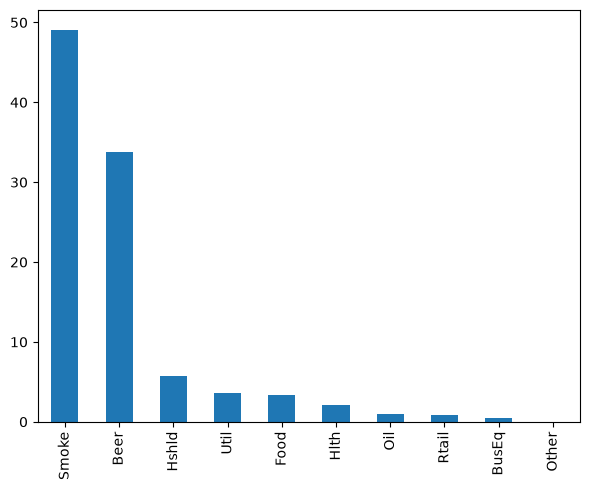

In [34]:
top10_weights = weights.sort_values(ascending=False).head(10)

plt.figure(figsize=(6, 5))
top10_weights.plot(kind='bar')
plt.tight_layout()
plt.show()

Now, contrast this with the results that would have been obtained if instead of a style analysis we use a regression. 

Hint: In this case you might need to sort the values in decreasing order before plotting.

In [35]:
import statsmodels.api as sm

# Agregar constante
X = sm.add_constant(ind)
model = sm.OLS(mgr_r, X).fit()


coeffs = model.params.drop("const") * 100

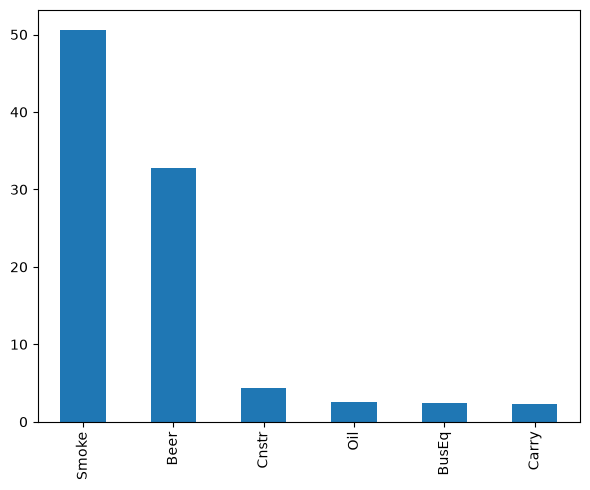

In [36]:
# Ordenar los coeficientes
coeffs_sorted = coeffs.sort_values(ascending=False).head(6)

# Graficar
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
coeffs_sorted.plot(kind='bar')
plt.tight_layout()
plt.show()

Why do you think the results look like this? What is the difference between the two methods or why are they producing different results?

Because the model is in fact very precise (i.e. we really did construct the manager's returns out of the building blocks), the results are remarkably accurate. However, the negative coefficients are hard to intepret and in real-life data, those will be much larger. However when it works well (as in this artificial example), the results can be very accurate. 

### Comparación entre Sharpe Style Analysis y Regresión OLS

Aunque ambos métodos tienen como objetivo identificar los factores que mejor replican los rendimientos del portafolio del manager, sus enfoques son distintos:

- **Sharpe Style Analysis** impone dos restricciones importantes:
  - Todos los pesos deben ser **positivos**
  - Los pesos deben **sumar 1**
  
  Esto simula de manera realista la construcción de un portafolio, como si estuviera formado por una combinación de activos reales.

- **La regresión OLS**, en cambio, no impone ninguna restricción:
  - Los coeficientes pueden ser **negativos o mayores a 100%**
  - Esto puede generar resultados difíciles de interpretar en términos de inversión real

En este caso particular, como el portafolio fue **artificialmente construido a partir de industrias reales**, ambos métodos identifican correctamente las industrias más relevantes (por ejemplo, **Smoke** y **Beer**).  
Sin embargo, la regresión OLS devuelve algunos coeficientes **ligeramente negativos o exagerados**, lo cual sería problemático en un escenario real.

En la práctica, el análisis de estilo suele preferirse cuando queremos entender **la exposición real de un portafolio**, ya que sus restricciones hacen que los resultados sean más interpretables en términos de construcción de portafolios.


**Potential Misuse of Style Analysis**

Style Analysis works best when the explanatory indices are in fact a good specification of what is happening. For instance, it usually gives you very useful and revealing insight if you use a stock market index (such as SPY) and other broad indices, ETFs or mutual funds (such as a Value Fund, a Growth Fund, an International Fund, a Bond Fund etc). Part of the skill in extracting meaningful results is to pick the right set of explanatory variables. However, a part of the challenge with Style Analysis is that it will always return a portfolio. It will still always give you an answer, even if it is an unreasonable one, and it's not always obvious how much one can rely on the result.

For instance, we can try and extract the major industries that BRKA invested in since 2000 as follows:

In [37]:
mgr_r_b = brka_m.loc["2000":, "BRKA"] #brka monthly returns from 200 onwards
#apply sharpe style analysis
weights_b = style_analysis(mgr_r_b, ind)
weights_b.sort_values(ascending=False).head(6).round(4)*100

Food     41.35
Fin      17.61
Meals    12.11
Other    11.03
Util      7.19
Clths     5.99
dtype: float64

If we want to look at the last decade (2009-2018):

In [38]:
mgr_r_b = brka_m.loc["2009":"2018", "BRKA"]
ind = df_ind.loc["2009":"2018"]
# Aplicar análisis de estilo con industrias como factores
weights_b = style_analysis(mgr_r_b, ind)

# Mostrar los 6 factores con mayor peso (en %)
weights_b.sort_values(ascending=False).head(6).round(4) * 100

Other    43.64
Food     28.33
Hlth     22.72
Rtail     5.25
Meals     0.07
Util      0.00
dtype: float64

Should you believe the analysis? Why? 

Thus, even when we need to care about the results, when the specification is in fact accurate (as we saw in 
the articially generated series) the results can be very revealing.

### ¿Deberías confiar en el análisis? ¿Por qué?

El análisis de estilo proporciona una explicación matemáticamente optimizada de los retornos de BRKA utilizando los factores industriales disponibles. Dado que el método minimiza el error de seguimiento bajo restricciones específicas (pesos positivos que suman 1), los resultados son consistentes y útiles como herramienta de diagnóstico.

Sin embargo, es importante interpretar los resultados con precaución:

- En primer lugar, el análisis de estilo **siempre devuelve un portafolio**, incluso si los factores explicativos no son adecuados. Es decir, puede parecer preciso, pero aún así ser engañoso si las variables no representan bien las inversiones reales del portafolio.
- En este caso específico (2009–2018), el alto peso asignado a la categoría **"Other"** (43.64%) sugiere que una parte importante del comportamiento de BRKA **no está bien capturada** por las 30 industrias utilizadas. Esto limita cuánto podemos confiar en las asignaciones individuales.
- Además, la **ausencia del sector financie]ro** entre los principales factores —a pesar de las conocidas inversiones de BRKA en ese sector— puede reflejar tanto un cambio en la dinámica de los retornos como una **limitación en los datos explicativos**.

El análisis es **útil como herramienta exploratoria**, sobre todo para comparar diferentes periodos o detectar posibles cambios en el estilo de inversión. Sin embargo, **no debe tomarse como una descomposición definitiva del portafolio**. Su confiabilidad depende en gran medida de la **relevancia y calidad de los factores utilizados**.


## Exploring Further Factor and Style Analysis 

**Factor Analysis for Industries**

We can extend the factor analysis from individual companies returns to industry returns. Load the 49 Value Weighted industry portfolio returns. Limit the analysis to returns of the 49 VW portfolios from 1991 onwards (1991 included, 1990 not included, 2018 included). Also load the Fama French Research Factors over the same period. Use the Mkt-RF to evaluate the CAPM (Single Factor) Betas over the entire period (1991-2018) for the excess return of Beer and Steel? How do these change when considering 2013 to 2018 period? When evaluating for all the induestries from 1991-1993, what had the highest and lowest CAPM betas and how to interpret it?

Now, use the FF 3 factor model, of the 49 industries, which displayed the highest Small Cap, which the highest Large Cap, the highest Value, and highest Growth tilt when analyzed over the entire period? How can we interpret these results?


In [39]:
df_ind_49 = pd.read_csv(f"../data/ind49_m_vw_rets.csv", header=0, index_col=0, na_values=-99.99)/100
df_ind_49.index = pd.to_datetime(df_ind_49.index, format="%Y%m").to_period('M')
df_ind_49.columns = df_ind_49.columns.str.strip()

In [40]:
ind_49 = df_ind_49["1991":]
ind_49.head()

,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
1991-01,0.0699,0.0312,0.0563,0.0465,0.0268,0.1191,0.0498,0.0936,0.0081,0.1821,...,0.1248,0.1230,0.0309,0.1174,0.0137,0.0823,0.0626,0.0312,0.0736,0.1240
1991-02,0.1038,0.1200,0.0751,0.1084,0.0768,0.1752,0.1019,0.0332,0.0639,0.1453,...,0.0523,0.0545,0.0849,0.0765,0.1331,0.1238,0.0918,0.1382,0.1155,0.0693
1991-03,0.0240,0.0612,0.0589,0.0567,0.0137,0.0439,-0.0231,0.0055,0.0414,0.0397,...,0.0826,-0.0194,0.0321,0.0935,0.1012,0.0481,0.0525,0.0827,0.0961,-0.0378
1991-04,-0.0071,-0.0084,-0.0188,-0.0401,-0.0347,0.0293,-0.0364,0.0301,-0.0144,0.0159,...,-0.0028,0.0363,0.0150,0.0263,-0.0240,0.0605,-0.0184,-0.0014,0.0094,-0.0010
1991-05,0.1075,0.0267,0.0310,0.0386,0.0394,0.0414,0.0393,0.0438,0.0405,0.0102,...,0.0505,0.0786,0.0659,0.0813,0.0484,0.0704,0.0260,-0.0234,0.0414,0.0407


In [41]:
fama = pd.read_csv("../data/F-F_Research_Data_Factors_m.csv", header=0, index_col=0, na_values=-99.99)/100 
fama.index = pd.to_datetime(fama.index, format="%Y%m").to_period('M') 

In [42]:
explicatorias = fama.loc["1991":, ["Mkt-RF"]].copy()
explicatorias["Constant"] = 1
explicatorias["Value"] = fama.loc["1991":, "HML"]
explicatorias["Size"] = fama.loc["1991":, "SMB"]
explicatorias.head()

,Mkt-RF,Constant,Value,Size
1991-01,0.0469,1,-0.0184,0.0379
1991-02,0.0719,1,-0.0054,0.0395
1991-03,0.0265,1,-0.0123,0.0389
1991-04,-0.0028,1,0.0142,0.0050
1991-05,0.0365,1,-0.0057,-0.0034


In [43]:
#Análisis de un factor para Beer y Steel
capm = fama.loc["1991":, ["Mkt-RF"]].copy()
capm["Constant"] = 1
capm.head()

,Mkt-RF,Constant
1991-01,0.0469,1
1991-02,0.0719,1
1991-03,0.0265,1
1991-04,-0.0028,1
1991-05,0.0365,1


In [44]:
#De 1991 en adelante
beer_excess = pd.DataFrame(ind_49["Beer"] - fama["RF"], columns=["Beer"])
beer_excess = beer_excess.loc["1991":].copy()
steel_excess = pd.DataFrame(ind_49["Steel"] - fama["RF"], columns=["Steel"])
steel_excess = steel_excess.loc["1991":].copy()

In [45]:
comun_beer = beer_excess.index.intersection(capm.index)
regresion_beer = sm.OLS(beer_excess.loc[comun_beer], capm.loc[comun_beer]).fit() 
regresion_beer.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Beer   R-squared:                       0.226
Model:                            OLS   Adj. R-squared:                  0.224
Method:                 Least Squares   F-statistic:                     97.55
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.37e-20
Time:                        15:54:11   Log-Likelihood:                 596.94
No. Observations:                 336   AIC:                            -1190.
Df Residuals:                     334   BIC:                            -1182.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         0.5295      0.054      9.877      0.000       0.424       0.635
Constant       0.0043      0.002      1.892      0.059      -0.000       0.009
==============================================================================
Omnibus:                       20.697   Durbin-Watson:                   2.079
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               43.130
Skew:                          -0.314   Prob(JB):                     4.31e-10
Kurtosis:                       4.639   Cond. No.                         23.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [46]:
comun_steel = steel_excess.index.intersection(capm.index)
regresion_steel = sm.OLS(steel_excess.loc[comun_steel], capm.loc[comun_steel]).fit() 
regresion_steel.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Steel   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     572.0
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.29e-74
Time:                        15:54:11   Log-Likelihood:                 532.25
No. Observations:                 336   AIC:                            -1061.
Df Residuals:                     334   BIC:                            -1053.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         1.5546      0.065     23.917      0.000       1.427       1.682
Constant      -0.0055      0.003     -2.014      0.045      -0.011      -0.000
==============================================================================
Omnibus:                       24.614   Durbin-Watson:                   2.016
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               42.413
Skew:                           0.456   Prob(JB):                     6.17e-10
Kurtosis:                       4.482   Cond. No.                         23.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Comparación CAPM entre las industrias Beer y Steel (1991–2018)

El modelo CAPM fue aplicado a los retornos mensuales de las industrias Beer y Steel durante el periodo 1991–2018, revelando importantes diferencias en su comportamiento frente al mercado.

La industria **Beer** presentó una beta de aproximadamente **0.53**, lo cual indica que sus retornos son considerablemente menos volátiles que los del mercado. Esto concuerda con su carácter de industria defensiva, vinculada al consumo básico. Su alpha fue positivo pero pequeño (**0.43% mensual**) y **no estadísticamente significativo**, lo que sugiere que no hay evidencia sólida de que haya generado rendimientos extraordinarios una vez ajustado por riesgo. Además, el R-cuadrado fue de **0.226**, lo que implica que solo una cuarta parte de la variabilidad en sus retornos es explicada por el mercado.

En contraste, la industria **Steel** mostró una beta de aproximadamente **1.55**, lo cual la clasifica como una industria altamente sensible al mercado, típica de sectores cíclicos o industriales. Su alpha fue negativo (**–0.55% mensual**) y **estadísticamente significativo**, lo que indica que, en promedio, sus rendimientos fueron menores a los que se esperaría dado su nivel de exposición al riesgo de mercado. El ajuste del modelo fue mucho más fuerte que en el caso anterior, con un R-cuadrado de **0.631**, lo que sugiere que el CAPM explica más del 60% de la variabilidad de sus retornos.

En resumen, estos resultados reflejan diferencias sustanciales en el estilo y comportamiento de ambas industrias. Mientras **Beer** actúa como un activo más estable y poco dependiente del mercado, **Steel** responde de forma más amplificada a los movimientos del mismo, con mayor riesgo pero también con rendimientos que, en este caso, no compensaron ese riesgo adicional.

In [47]:
#Ahora de 2013 a 2018
beer_excess_2013 = pd.DataFrame(ind_49["Beer"] - fama["RF"], columns=["Beer"])
beer_excess_2013 = beer_excess_2013.loc["2013":].copy()
steel_excess_2013 = pd.DataFrame(ind_49["Steel"] - fama["RF"], columns=["Steel"])
steel_excess_2013 = steel_excess_2013.loc["2013":].copy()

In [48]:
comun_beer = beer_excess_2013.index.intersection(capm.index)
regresion_beer_2013 = sm.OLS(beer_excess_2013.loc[comun_beer], capm.loc[comun_beer]).fit() 
regresion_beer_2013.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Beer   R-squared:                       0.313
Model:                            OLS   Adj. R-squared:                  0.303
Method:                 Least Squares   F-statistic:                     31.87
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           3.27e-07
Time:                        15:54:11   Log-Likelihood:                 155.66
No. Observations:                  72   AIC:                            -307.3
Df Residuals:                      70   BIC:                            -302.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         0.5860      0.104      5.645      0.000       0.379       0.793
Constant       0.0045      0.003      1.289      0.201      -0.002       0.011
==============================================================================
Omnibus:                        5.069   Durbin-Watson:                   2.196
Prob(Omnibus):                  0.079   Jarque-Bera (JB):                4.535
Skew:                          -0.610   Prob(JB):                        0.104
Kurtosis:                       3.155   Cond. No.                         31.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [49]:
comun_steel = steel_excess_2013.index.intersection(capm.index)
regresion_steel_2013 = sm.OLS(steel_excess_2013.loc[comun_steel], capm.loc[comun_steel]).fit() 
regresion_steel_2013.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Steel   R-squared:                       0.470
Model:                            OLS   Adj. R-squared:                  0.463
Method:                 Least Squares   F-statistic:                     62.18
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.97e-11
Time:                        15:54:11   Log-Likelihood:                 116.15
No. Observations:                  72   AIC:                            -228.3
Df Residuals:                      70   BIC:                            -223.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         1.4169      0.180      7.885      0.000       1.059       1.775
Constant      -0.0098      0.006     -1.627      0.108      -0.022       0.002
==============================================================================
Omnibus:                        7.128   Durbin-Watson:                   2.188
Prob(Omnibus):                  0.028   Jarque-Bera (JB):                6.420
Skew:                           0.635   Prob(JB):                       0.0403
Kurtosis:                       3.727   Cond. No.                         31.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Comparación Temporal del Modelo CAPM: Industrias Beer y Steel

Se aplicó el modelo CAPM a las industrias Beer y Steel para comparar su comportamiento durante el periodo completo (1991–2018) frente a la etapa más reciente (2013–2018). 

En el caso de **Beer**, la beta pasó de **0.53** a **0.59**, lo que indica un leve aumento en su sensibilidad al mercado, aunque se mantiene por debajo de 1, reafirmando su perfil defensivo. El alpha (0.0045) se mantuvo positivo pero **no fue estadísticamente significativo** en ninguno de los periodos. El R-cuadrado aumentó de **0.226 a 0.313**, lo que implica que el CAPM logra explicar mejor sus retornos en años recientes.

Para **Steel**, la beta se redujo ligeramente de **1.55** a **1.42**, pero sigue siendo muy superior a 1, confirmando que se trata de una industria altamente cíclica. El alpha fue negativo en ambos periodos (**–0.0055** en 1991–2018 y **–0.0098** en 2013–2018), aunque en la etapa reciente **ya no fue estadísticamente significativo**. El R-cuadrado cayó de **0.631 a 0.470**, indicando que la capacidad explicativa del CAPM fue menor en esta última etapa.

#### ¿Por qué ocurren estos cambios?

Los cambios observados pueden explicarse por distintos factores económicos y estructurales:

- En el caso de **Beer**, el leve aumento en beta y en R-cuadrado podría deberse a una **mayor integración con los movimientos generales del mercado** en años recientes, posiblemente por consolidaciones empresariales, cambios en la cadena de suministro global o una mayor exposición internacional que la vuelve ligeramente más sensible a shocks macroeconómicos.

- En contraste, la reducción en la beta de **Steel** podría reflejar **menor exposición al ciclo económico mundial** o una **diversificación geográfica** de la producción. Sin embargo, el descenso del R² sugiere que el comportamiento de esta industria **ya no está tan alineado exclusivamente con el mercado**, y que **otros factores específicos** (como precios de materias primas, política comercial o regulación ambiental) podrían haber ganado mayor relevancia.

- En general, la caída en la significancia del alpha para ambas industrias también puede reflejar un entorno más competitivo y eficiente, donde es más difícil generar rendimientos sistemáticamente distintos al mercado una vez ajustados por riesgo.

### Conclusión:

Ambas industrias conservaron sus características estructurales: **Beer como defensiva** con baja beta y Steel como **cíclica con alta exposición al mercado**. No obstante, los ligeros cambios en las magnitudes de las betas y en la calidad del ajuste del modelo reflejan **una evolución en la forma en que estas industrias interactúan con el mercado**. Esto resalta la importancia de analizar los modelos de riesgo en distintos horizontes temporales para identificar posibles transiciones o cambios en el comportamiento de los sectores.


In [50]:
#Ahora para todas las empresas de 1991 a 1993
exceso = pd.DataFrame()
for col in ind_49.columns:
    entrada = pd.DataFrame(ind_49[col] - fama["RF"], columns=[col])
    entrada = entrada.loc["1991":"1993"].copy()
    exceso[col] = entrada

In [51]:
resultados = {}
for col in exceso.columns:
    comun = exceso[col].index.intersection(capm.index)
    regresion = sm.OLS(exceso[col].loc[comun], capm.loc[comun]).fit()
    resultados[col] = regresion

In [52]:
#Para saber los resultados de una empresa
resultados["Food"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Food   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                     45.27
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           9.91e-08
Time:                        15:54:11   Log-Likelihood:                 71.046
No. Observations:                  36   AIC:                            -138.1
Df Residuals:                      34   BIC:                            -134.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         1.2626      0.188      6.729      0.000       0.881       1.644
Constant      -0.0089      0.006     -1.448      0.157      -0.021       0.004
==============================================================================
Omnibus:                        0.363   Durbin-Watson:                   1.493
Prob(Omnibus):                  0.834   Jarque-Bera (JB):                0.262
Skew:                           0.195   Prob(JB):                        0.877
Kurtosis:                       2.852   Cond. No.                         32.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [53]:
#Serie con los coeficientes
betas = {industry: resultados[industry].params["Mkt-RF"] for industry in resultados}
betas_series = pd.Series(betas)
betas_series = betas_series.sort_values(ascending=False)
betas_series.head()

Hlth     1.615195
Softw    1.608340
Cnstr    1.520882
Clths    1.516927
MedEq    1.473925
dtype: float64

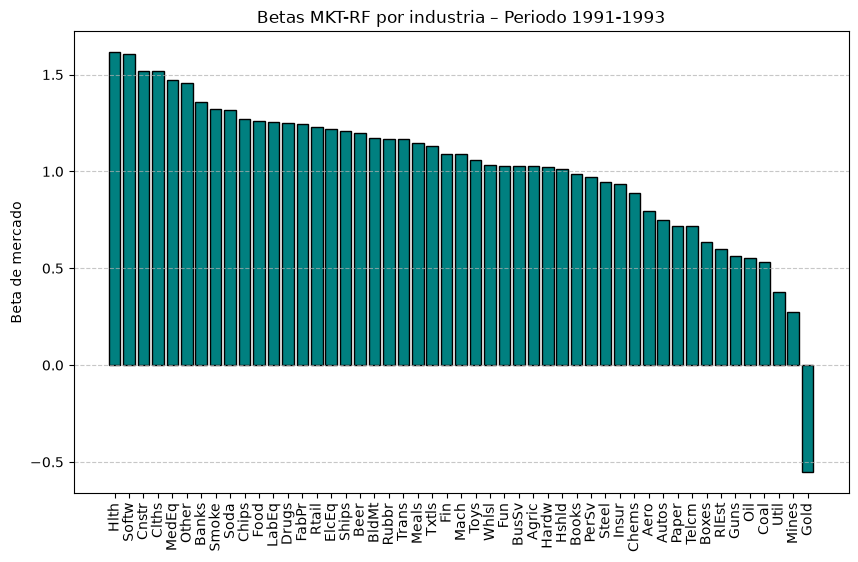

In [54]:
#Gráfica de las betas
plt.figure(figsize=(10, 6))
plt.bar(betas_series.index, betas_series.values, color="teal", edgecolor="black")
plt.xticks(rotation=90)
plt.title("Betas MKT-RF por industria – Periodo 1991-1993")
plt.ylabel("Beta de mercado")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Estimando las betas del modelo CAPM para las 49 industrias durante el periodo de 1991 a 1993, utilizando el exceso de retorno del mercado como variable explicativa. Este análisis permite identificar qué industrias fueron más sensibles al comportamiento del mercado, y cuáles actuaron de forma más defensiva o incluso contra-cíclica.

Las cinco industrias que presentaron las betas más altas fueron Hlth, Softw, Cnstr, Clths y MedEq, todas con betas superiores a 1.47 y la mayor alcanzando un valor de 1.61. Esto significa que estas industrias fueron altamente sensibles al mercado en ese periodo. Resulta interesante que sectores como salud y tecnología, que en otros periodos podrían clasificarse como defensivos o estables, mostraron en estos años una fuerte exposición sistemática, posiblemente debido a un entorno de expansión económica, innovación o crecimiento acelerado.

Por otro lado, las industrias con las betas más bajas fueron Gold, Mines, Util, Coal y Oil. En particular, el oro mostró una beta negativa de aproximadamente –0.55, lo que indica que sus retornos tendieron a moverse en dirección contraria al mercado, comportamiento consistente con su uso como activo refugio. Utilities, minería y energía, por su parte, presentaron una menor sensibilidad al mercado, lo que refleja su carácter más estable, menos expuesto a los ciclos económicos y con ingresos más predecibles.

En resumen, este análisis revela que las industrias no responden de la misma manera al riesgo sistemático. Algunas se comportan de forma amplificada frente a los movimientos del mercado, mientras que otras actúan como estabilizadores dentro de un portafolio. Estos resultados son claves para la diversificación y la gestión del riesgo en la construcción de carteras.

In [55]:
#Ahora el modelo Fama-French (1991 en adelante)
exceso_famoso = pd.DataFrame()
for col in ind_49.columns:
    entrada = pd.DataFrame(ind_49[col] - fama["RF"], columns=[col])
    entrada = entrada.loc["1991":].copy()
    exceso_famoso[col] = entrada

In [56]:
resultados_famosos = {}
for col in exceso_famoso.columns:
    comun = exceso_famoso[col].index.intersection(explicatorias.index)
    regresion = sm.OLS(exceso_famoso[col].loc[comun], explicatorias.loc[comun]).fit()
    resultados_famosos[col] = regresion

In [57]:
#Resultados del modelo Fama-French
resultados_famosos["Food"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Food   R-squared:                       0.338
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     56.44
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           1.66e-29
Time:                        15:54:12   Log-Likelihood:                 674.79
No. Observations:                 336   AIC:                            -1342.
Df Residuals:                     332   BIC:                            -1326.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mkt-RF         0.5581      0.044     12.689      0.000       0.472       0.645
Constant       0.0025      0.002      1.371      0.171      -0.001       0.006
Value          0.1565      0.062      2.511      0.013       0.034       0.279
Size          -0.2679      0.059     -4.558      0.000      -0.383      -0.152
==============================================================================
Omnibus:                       34.333   Durbin-Watson:                   1.867
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.686
Skew:                           0.386   Prob(JB):                     5.59e-25
Kurtosis:                       5.717   Cond. No.                         38.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [58]:
betas_famosas = pd.DataFrame({industry: resultados_famosos[industry].params[["Mkt-RF", "Size", "Value"]] for industry in resultados_famosos}).T
betas_famosas.head()

,Mkt-RF,Size,Value
Agric,0.684404,0.165856,0.131897
Food,0.558117,-0.267873,0.156536
Soda,0.817167,-0.121587,0.397642
Beer,0.590261,-0.358655,0.006329
Smoke,0.590791,-0.307794,0.266018


In [59]:
beta_MKT_RF = betas_famosas["Mkt-RF"].sort_values(ascending=False)
beta_Size = betas_famosas["Size"].sort_values(ascending=False)
beta_Value = betas_famosas["Value"].sort_values(ascending=False)

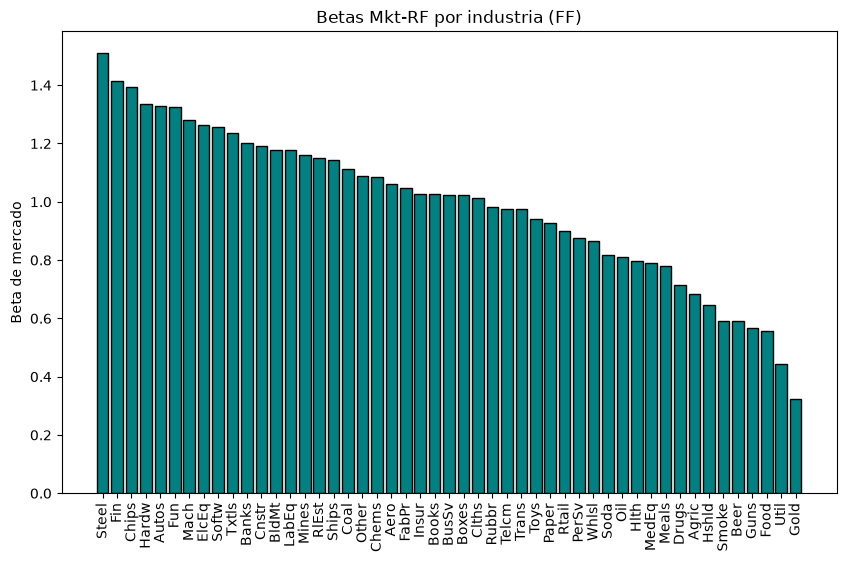

In [60]:
#Beta de exceso de mercado
plt.figure(figsize=(10, 6))
plt.bar(beta_MKT_RF.index, beta_MKT_RF.values, color="teal", edgecolor="black")
plt.title(f"Betas Mkt-RF por industria (FF)")
plt.ylabel("Beta de mercado")
plt.xticks(rotation=90)
plt.show()

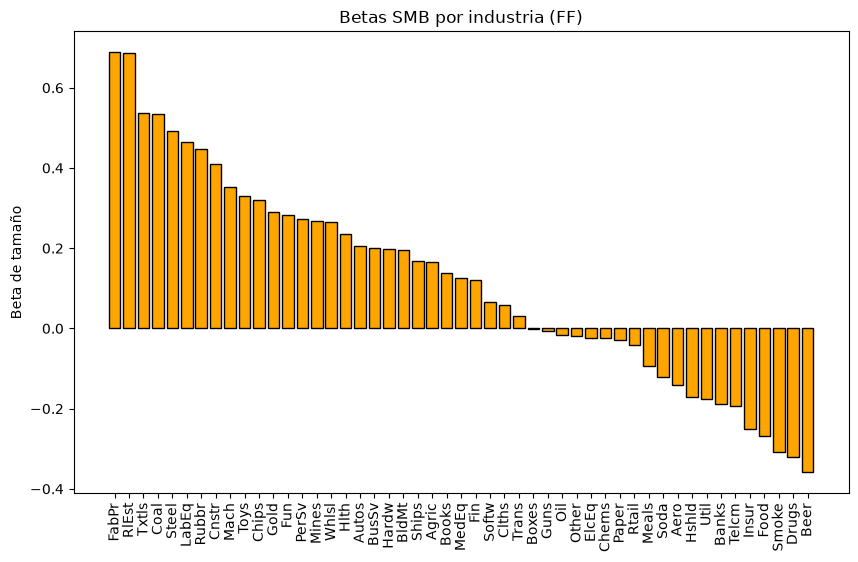

In [61]:
#Beta de tamaño
plt.figure(figsize=(10, 6))
plt.bar(beta_Size.index, beta_Size.values, color="orange", edgecolor="black")
plt.title(f"Betas SMB por industria (FF)")
plt.ylabel("Beta de tamaño")
plt.xticks(rotation=90)
plt.show()

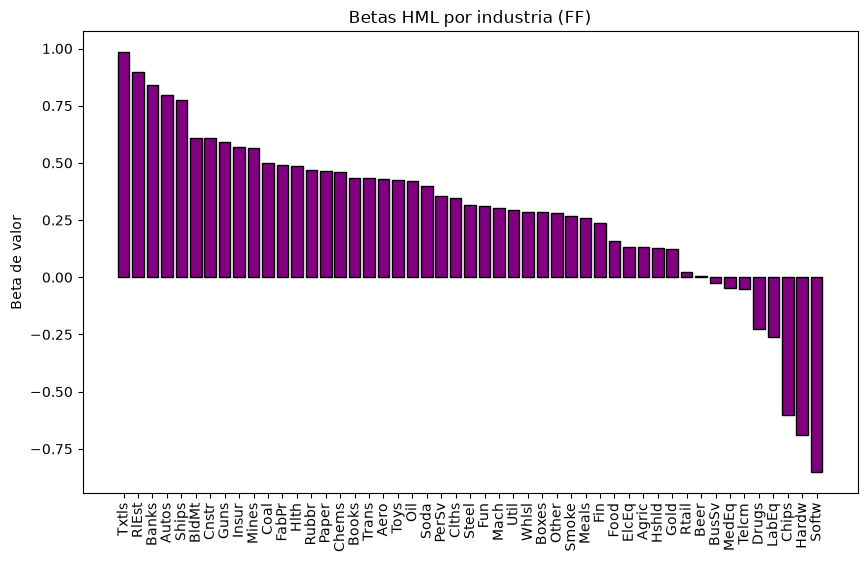

In [62]:
#Beta de valor
plt.figure(figsize=(10, 6))
plt.bar(beta_Value.index, beta_Value.values, color="purple", edgecolor="black")
plt.title(f"Betas HML por industria (FF)")
plt.ylabel("Beta de valor")
plt.xticks(rotation=90)
plt.show()

### Análisis de Exposición a Factores Fama-French (1991–2018)

Con base en el modelo Fama-French de tres factores aplicado a las 49 industrias durante el periodo 1991–2018, se obtuvieron los coeficientes que reflejan la exposición de cada industria al tamaño (SMB) y al estilo de inversión (HML).

**Tamaño (SMB)**  
Las industrias con mayor exposición a **empresas pequeñas** fueron FabPr, RlEst, Txtls, Coal y Steel, con coeficientes SMB entre **0.49 y 0.69**. Esto sugiere que estas industrias se comportan de forma similar a portafolios que invierten en compañías de baja capitalización, más volátiles y con mayor potencial de crecimiento.

Por otro lado, las industrias con mayor exposición a **empresas grandes** (coeficientes SMB negativos) fueron Insur, Food, Smoke, Drugs y Beer, con valores cercanos a **-0.26 a -0.36**. Estas industrias tienden a comportarse como portafolios más conservadores y estables, asociados a compañías de gran capitalización.

**Estilo Valor vs. Crecimiento (HML)**  
En cuanto al estilo de inversión, las industrias más asociadas a **empresas de valor** (coeficientes HML altos) fueron Txtls, RlEst, Banks, Autos y Ships, con coeficientes superiores a **0.77**, lo cual indica una inclinación hacia empresas con alta relación valor contable/precio, típicas de sectores tradicionales.

En contraste, las industrias con mayor exposición a **empresas de crecimiento** (coeficientes HML negativos) fueron Drugs, LabEq, Chips, Hardw y Softw, con valores entre **-0.22 y -0.85**. Esto sugiere un comportamiento alineado con sectores innovadores, intensivos en tecnología y con altas tasas de reinversión, como la salud y la informática.

**Conclusión**  
El análisis revela diferencias marcadas entre industrias en términos de exposición a factores de tamaño y estilo. Estos resultados son clave para el diseño de estrategias de inversión diversificadas y coherentes con objetivos de riesgo-retorno, especialmente en carteras multifactoriales.


**Style Drift**

Similar to what you did before with factor analysis for BRKA changing the time window, one of the most common ways in which Sharpe Style Analysis can be used is to measure style drift. If you run the style analysis function over a rolling window of 1 to 5 years, you can extract changes in the style exposures 
of a manager. Perform the Style Drift Analysis for BRKA and the other company you selected (before Sharpe Style Analysis section) from 1995 to 2015 using a 5-year rolling window using the FF factors for these years and report your findings.

In [63]:
# Filtramos datos entre 1995 y 2015
brka_m_filtro = brka_m.loc["1995":"2015"].copy()
fff_filtro = fff.loc["1995":"2015"].copy()

# Exceso de retorno de BRKA 
brka_excess = brka_m_filtro["BRKA"] - fff_filtro["RF"]

# Factores de estilo (Value y Size)
style_factors = fff_filtro[["Mkt-RF","HML", "SMB"]]

In [64]:
# 1995-1999
brka_95_99 = brka_excess.iloc[0:60]
factors_95_99 = style_factors.iloc[0:60]
w_95_99 = style_analysis(brka_95_99, factors_95_99)
w_95_99

Mkt-RF    7.323675e-01
HML       2.676325e-01
SMB       1.247691e-16
dtype: float64

In [65]:
# 2000-2004
brka_00_04 = brka_excess.iloc[60:120]
factors_00_04 = style_factors.iloc[60:120]
w_00_04 = style_analysis(brka_00_04, factors_00_04)
w_00_04

Mkt-RF    0.366823
HML       0.633177
SMB       0.000000
dtype: float64

In [66]:
# 2005-2009
brka_05_09 = brka_excess.iloc[120:180]
factors_05_09 = style_factors.iloc[120:180]
w_05_09 = style_analysis(brka_05_09, factors_05_09)
w_05_09

Mkt-RF    4.678353e-01
HML       5.321647e-01
SMB       2.419086e-18
dtype: float64

In [67]:
# 2010-2015
brka_10_15 = brka_excess.iloc[180:240]
factors_10_15 = style_factors.iloc[180:240]
w_10_15 = style_analysis(brka_10_15, factors_10_15)
w_10_15

Mkt-RF    4.836563e-01
HML       5.163437e-01
SMB       1.734723e-18
dtype: float64

In [68]:
# Tabla con todos los datos
tabla_datos = pd.DataFrame({
    "Periodo": ["1995-1999", "2000-2004", "2005-2009", "2010-2015"],
    "Mkt-RF": [w_95_99["Mkt-RF"], w_00_04["Mkt-RF"], w_05_09["Mkt-RF"], w_10_15["Mkt-RF"]],
    "HML": [w_95_99["HML"], w_00_04["HML"], w_05_09["HML"], w_10_15["HML"]],
    "SMB": [w_95_99["SMB"], w_00_04["SMB"], w_05_09["SMB"], w_10_15["SMB"]]
})

print(tabla_datos.round(3))

     Periodo  Mkt-RF    HML  SMB
0  1995-1999   0.732  0.268  0.0
1  2000-2004   0.367  0.633  0.0
2  2005-2009   0.468  0.532  0.0
3  2010-2015   0.484  0.516  0.0


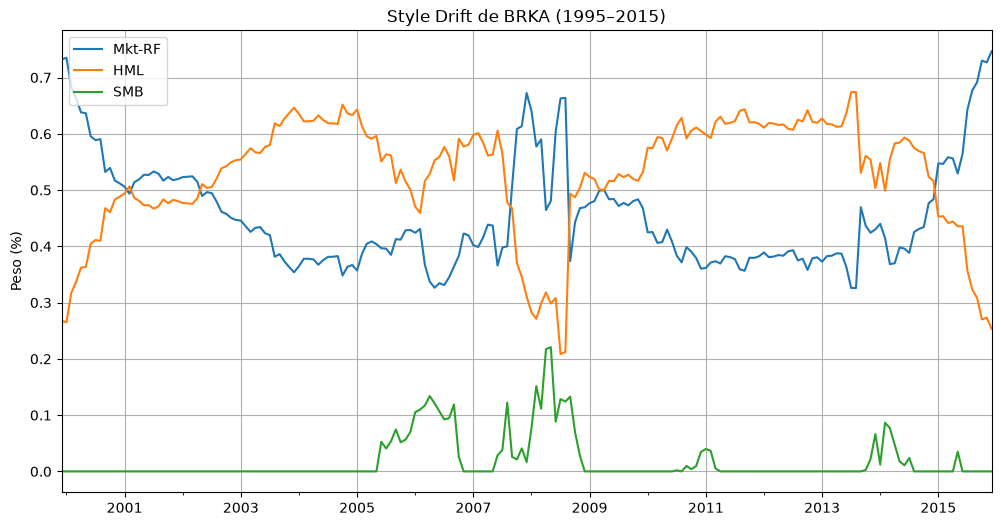

In [69]:
#Grafica chida pero xd
# Creamos listas vacías
rolling_weights = []
rolling_dates = []

# Estimaciones móviles usando style_analysis 
for i in range(len(brka_excess) - 60 + 1):
    sub_ret = brka_excess.iloc[i:i+60]
    sub_fac = style_factors.iloc[i:i+60]
    peso = style_analysis(sub_ret, sub_fac)
    rolling_weights.append(peso)
    rolling_dates.append(brka_excess.index[i + 59])  # Última fecha de la ventana

# Convertimos a DataFrame
rolling_weights_df = pd.DataFrame(rolling_weights, index=rolling_dates)

# Graficar evolución
rolling_weights_df.plot(figsize=(12, 6), title="Style Drift de BRKA (1995–2015)")
plt.ylabel("Peso (%)")
plt.grid(True)
plt.show()

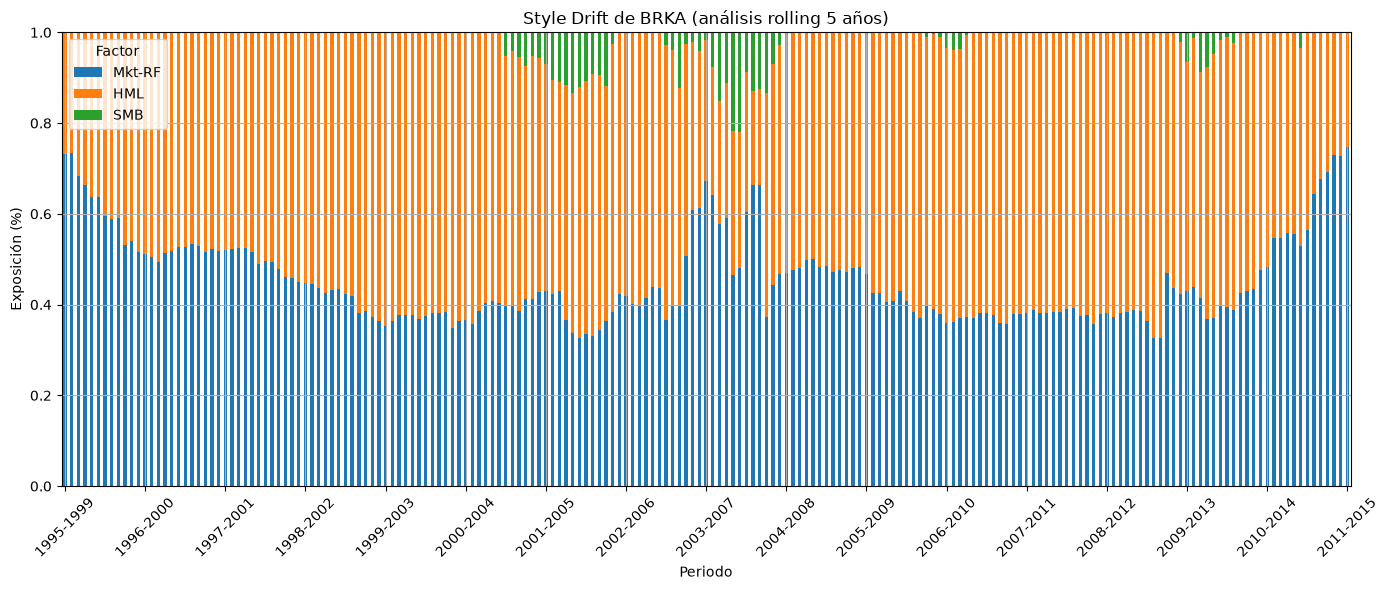

In [70]:
# Rolling de 60 meses (5 años)
window = 60
style_drift = []
fechas = []

# Rolling para BRKA
for i in range(len(brka_excess) - window + 1):
    r_fondo = brka_excess.iloc[i:i+window]
    r_etfs = style_factors.iloc[i:i+window]

    weights = style_analysis(r_fondo, r_etfs)
    style_drift.append(weights)
    
    # Formato "1995-1999"
    inicio = r_fondo.index[0].strftime('%Y')
    fin = r_fondo.index[-1].strftime('%Y')
    fechas.append(f"{inicio}-{fin}")

# Convertimos a DataFrame
style_drift_df = pd.DataFrame(style_drift, index=fechas)

# Gráfica de barras apiladas
style_drift_df.plot(kind="bar", stacked=True, figsize=(14, 6))
plt.title("Style Drift de BRKA (análisis rolling 5 años)")
plt.ylabel("Exposición (%)")
plt.xlabel("Periodo")

# Mostrar etiquetas cada N barras 
N = 12
plt.xticks(ticks=range(0, len(fechas), N), labels=fechas[::N], rotation=45)

plt.legend(title="Factor")
plt.tight_layout()
plt.grid(True)
plt.show()

In [71]:
xbrka_blocks = style_drift_df.iloc[::60].round(4)

display(xbrka_blocks)

,Mkt-RF,HML,SMB
1995-1999,0.7324,0.2676,0.0
2000-2004,0.3668,0.6332,0.0
2005-2009,0.4678,0.5322,0.0
2010-2014,0.4837,0.5163,0.0


[*********************100%***********************]  1 of 1 completed


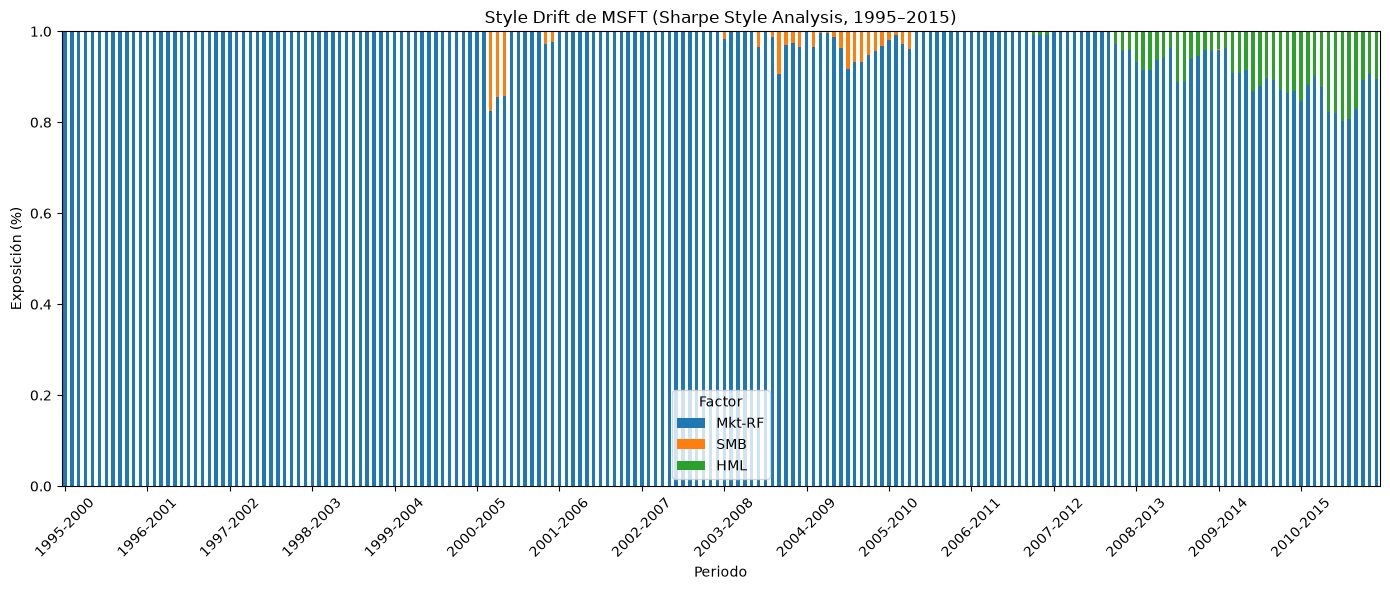

In [72]:
import yfinance as yf

#Datos de Microsoft mensualmente
#msft = yf.download("BRK-A", start="1995-01-01", end="2015-12-31", interval="1mo", auto_adjust=True)["Close"] #Línea para probar si funciona con BRKA
msft = yf.download("MSFT", start="1995-01-01", end="2015-12-31", interval="1mo", auto_adjust=True)["Close"]
msft_returns = msft.pct_change().dropna()
msft_returns.index = msft_returns.index.to_period("M")

#Datos
data = pd.concat([msft_returns, fff], axis=1).dropna()
data.columns = ["MSFT", "Mkt-RF", "SMB", "HML", "RF"]
data["MSFT_excess"] = data["MSFT"] - data["RF"]

#Rolling window style analysis 5 años
window = 60
style_weights = []
labels = []

r_msft = data["MSFT_excess"]
factors = data[["Mkt-RF", "SMB", "HML"]]

for i in range(len(data) - window + 1):
    r_window = r_msft.iloc[i:i+window]
    x_window = factors.iloc[i:i+window]
    weights = style_analysis(r_window, x_window)
    style_weights.append(weights)
    start = r_window.index[0].strftime("%Y")
    end = r_window.index[-1].strftime("%Y")
    labels.append(f"{start}-{end}")

msft_drift_df = pd.DataFrame(style_weights, index=labels)

#Gráfica
msft_drift_df.plot(kind="bar", stacked=True, figsize=(14, 6))
plt.title("Style Drift de MSFT (Sharpe Style Analysis, 1995–2015)")
plt.ylabel("Exposición (%)")
plt.xlabel("Periodo")

N = 12
plt.xticks(ticks=range(0, len(msft_drift_df), N), labels=msft_drift_df.index[::N], rotation=45)

plt.legend(title="Factor")
plt.tight_layout()
plt.show()

In [73]:
msft_blocks = msft_drift_df.iloc[::60].round(4)

display(msft_blocks)

,Mkt-RF,SMB,HML
1995-2000,1.0000,0.0000,0.0000
2000-2005,1.0000,0.0000,0.0000
2005-2010,0.9819,0.0181,0.0000
2010-2015,0.8471,0.0000,0.1529


**Morningstar**

Now, the interesting analysis, where style drift analysis actually is leveraged, is to observe and measure style drift in a fund manager’s portfolio over time by analyzing changes in their exposure to different style factors (Growth vs. Value, Small vs. Large). The rolling window approach allows for a dynamic view of how a manager’s style evolves. This is an important tool for understanding whether a manager is sticking to their stated investment style or if there are significant deviations. Let's do an exercise to show this!

To use Sharpe Style Analysis and rolling windows to decompose and track a fund manager’s returns into different investment styles (changes) over time, you will use Value and Growth ETFs (e.g., SPYG and SPYV) along with Small-Cap (SLY) and Large-Cap (OEF) ETFs as explanatory variables to measure the style drift. Alternatively, you can use Fama-French factors (HML for Value and SMB for Size) to categorize mutual funds by style.

We will implement a methodology very similar to what is called "Style Box", which is a methodology used by Morningstar. Morningstar is a leading global financial services firm that provides investment research and management services. It is best known for offering data, analysis, and ratings on a wide range of financial products, including mutual funds, exchange-traded funds (ETFs), stocks, bonds, and other investment vehicles. 

One of Morningstar's well-known tools is the Morningstar Style Box, which categorizes mutual funds, ETFs, and other investment products based on two dimensions: size (market capitalization) and style (growth vs. value). The Style Box helps investors understand the fund’s investment strategy and the types of stocks it holds. The categories are:
- Size: Large-cap, Mid-cap, Small-cap
- Style: Value, Blend (neutral), Growth

Morningstar assigns a star rating to funds based on their historical performance, adjusted for risk and costs. These ratings help investors quickly assess the relative performance of a fund compared to similar funds in the same category.
- 5-Star Rating: Top performing funds.
- 1-Star Rating: Bottom performing funds.

The Morningstar rating system is widely used by investors and financial advisors to evaluate the quality of mutual funds and ETFs.

These are the instructions to reproduce the methodology using style analysis:

1. Select a Funds manager of your preference and download the data for one of the funds they manage for a time period of your interest of at least 20 years (e.g. 1995 to 2015). Some famous fund managers are Vanguard Funds, JPMorgan Funds, BlackRock Funds (e.g. iShares), T Rowe Price, PIMCO Funds, Invesco, American Funds. 

2. Select a set of ETFs and download its returns or adjusted closing prices to compute the returns from Yahoo Finance (or any other reliable source) over the time period you are interested in (e.g., from 1995 to 2015). Some famous ETFs are SPYG (Growth ETF), SPYV (Value ETF), SLY (Small-Cap ETF), and OEF (Large-Cap ETF). These ETFs will be used as your explanatory variables in the style analysis. If needed you can research about ETFs and these specific ETFs.

3. As alternative explanatory variables you will use the FF factors dataset. If you prefer, you can use the Fama-French factors for your style analysis.

4. To perform the style analysis, you will estimate the optimal weights for each explanatory variable (the ETFs or Fama-French factors) that minimize the tracking error between the fund manager’s portfolio returns and the portfolio of explanatory variables. The goal is to determine how much each style (growth, value, small-cap, large-cap) contributes to the fund manager's returns. Perform the Sharpe Style Analysis.

5.  A rolling window approach will be used to analyze style drift over time. In this case, you will use a 5-year rolling window. This means that for each 5-year period, you will calculate the fund manager’s style exposures, then move the window forward and repeat the analysis. Perform the style analysis using a 5-year rolling window to obtain the factor weights.

6. Measure and Plot Style Drift
After completing the rolling window analysis, you will have a series of optimal weights that indicate the exposure of the fund manager to each style (Growth, Value, Small-Cap, Large-Cap) over time. You can then plot these exposures to visualize how the fund manager’s style evolves. Plot the exposures for each style over time to observe whether the manager’s style is stable or drifting. The plot should show the proportion of each style (Growth, Value, Small-Cap, Large-Cap) in the portfolio at each point in time. Look for significant changes in style exposures over time. A manager sticking to their stated style will have relatively stable exposures, while a drifting manager may show large changes in style allocations.

You can now draw you conclusions on the results, and as an optional final tasks you can compare with Morningstar’s Style Box by going to the Morningstar website and search for the fund manager you are analyzing. Find the Style Box for that fund, which will show you the fund’s exposure to value and growth stocks, as well as small, mid, and large-cap stocks. Compare this categorization with your calculated style exposures to see if they align. Check whether the fund manager’s style has remained consistent, or whether there are significant changes (style drift) that are not reflected in the Morningstar Style Box.

In [74]:
import yfinance as yf

In [75]:
# Datos
start = "2004-01-01"
end = "2024-12-31"
fondo = "VFINX"
etfs = ["SPYG", "SPYV", "SLYV", "OEF"]

data = yf.download([fondo] + etfs, start=start, end=end, interval="1mo", auto_adjust=True)["Close"]

returns = data.pct_change().dropna()

fondo_ret = returns[fondo]
etfs_ret = returns[etfs]

[*********************100%***********************]  4 of 5 completed


In [76]:
window = 60
style_drift = []
fechas = []

for i in range(len(fondo_ret) - window + 1):
    r_fondo = fondo_ret.iloc[i:i+window]
    r_etfs = etfs_ret.iloc[i:i+window]
    
    weights = style_analysis(r_fondo, r_etfs)
    style_drift.append(weights)
    fechas.append(f"{r_fondo.index[0].strftime('%Y')}-{r_fondo.index[-1].strftime('%Y')}")

style_drift_df = pd.DataFrame(style_drift, index=fechas)

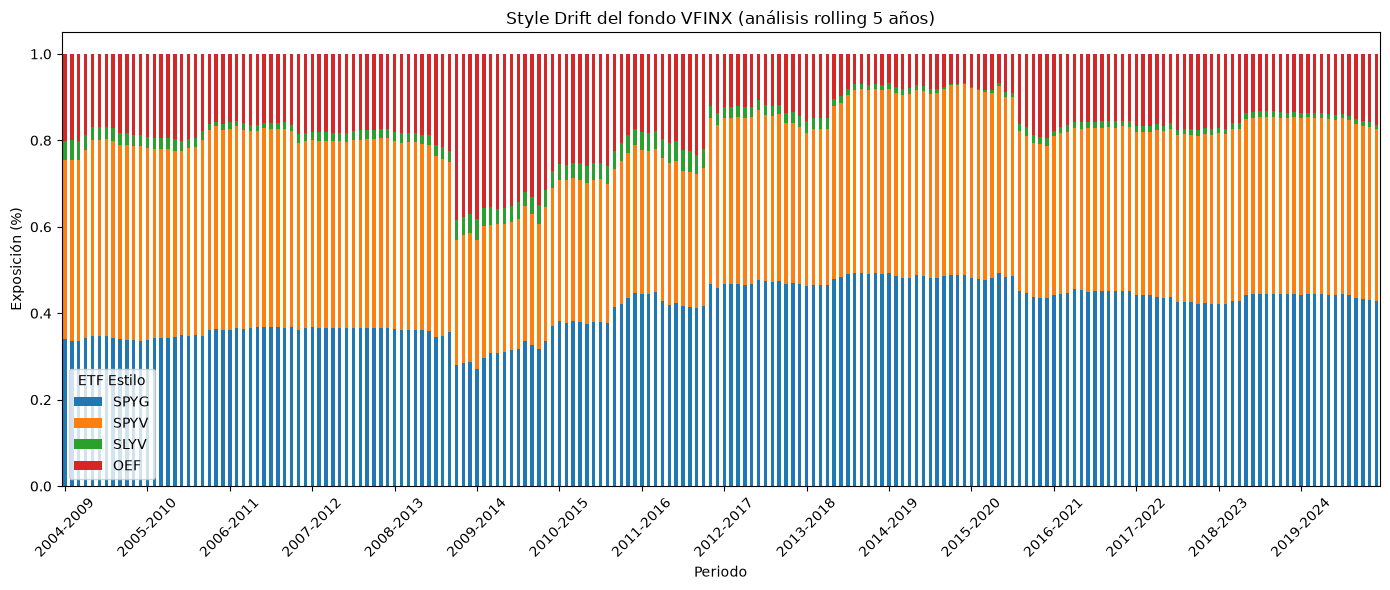

In [77]:
import matplotlib.pyplot as plt

# Gráfica
style_drift_df.plot(kind="bar", stacked=True, figsize=(14,6))
plt.title("Style Drift del fondo VFINX (análisis rolling 5 años)")
plt.ylabel("Exposición (%)")
plt.xlabel("Periodo")

N = 12 
plt.xticks(ticks=range(0, len(fechas), N), labels=fechas[::N], rotation=45)

plt.legend(title="ETF Estilo")
plt.tight_layout()
plt.show()

In [78]:
import pandas as pd

tabla_pesos = style_drift_df.round(4)

tabla_pesos

Ticker,SPYG,SPYV,SLYV,OEF
2004-2009,0.3400,0.4144,0.0449,0.2006
2004-2009,0.3366,0.4173,0.0460,0.2001
2004-2009,0.3353,0.4202,0.0436,0.2009
2004-2009,0.3437,0.4347,0.0349,0.1868
2004-2009,0.3472,0.4540,0.0287,0.1701
...,...,...,...,...
2019-2024,0.4416,0.4052,0.0099,0.1433
2019-2024,0.4359,0.4027,0.0106,0.1508
2019-2024,0.4320,0.4009,0.0108,0.1563
2019-2024,0.4309,0.4011,0.0103,0.1577


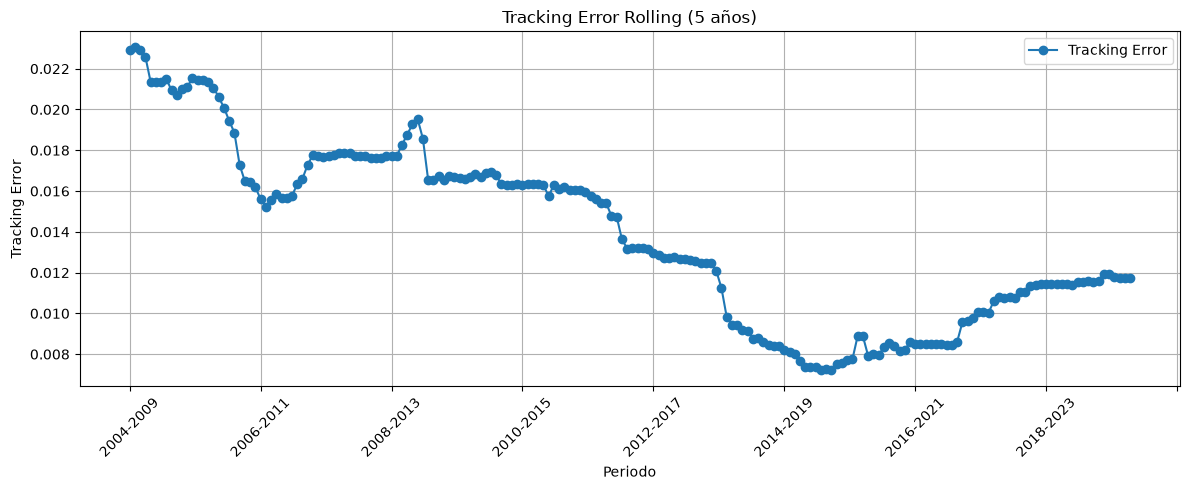

In [79]:
tracking_errors = []

for i in range(len(fondo_ret) - window + 1):
    r_fondo = fondo_ret.iloc[i:i+window]
    r_etfs = etfs_ret.iloc[i:i+window]
    
    weights = style_analysis(r_fondo, r_etfs)
    
    replicado = (r_etfs * weights).sum(axis=1)
    
    te = tracking_error(r_fondo, replicado)
    tracking_errors.append(te)

tracking_error_df = pd.DataFrame(tracking_errors, index=fechas, columns=["Tracking Error"])

tracking_error_df.plot(figsize=(12,5), marker='o', title="Tracking Error Rolling (5 años)")
plt.xlabel("Periodo")
plt.ylabel("Tracking Error")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [80]:
global_weights = style_analysis(fondo_ret, etfs_ret)

replicated = (etfs_ret * global_weights).sum(axis=1)

# Tracking error total
total_te = tracking_error(fondo_ret, replicated)
print(f"Tracking Error Total: {total_te:.4f}")

Tracking Error Total: 0.0346
